In [2]:
import sys
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib.ticker import StrMethodFormatter
plt.style.use('dark_background')

In [3]:
cwd = Path.cwd()
project_root = cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print('Done!')

Done!


In [4]:
data_path = project_root / 'data' / 'processed' / 'demand_development.csv'
demand_data = pd.read_csv(data_path)

In [5]:
utc_columns = [
    'timestamp_utc',
    'timestamp_london',
    'interval_end_utc',
    'forecast_issue_utc',
    'forecast_cutoff_utc',
    'scheduled_kickoff_utc',
]

for column in utc_columns:
    demand_data[column] = pd.to_datetime(
        demand_data[column], utc=True
    )

In [6]:
demand_data['timestamp_london'] = demand_data['timestamp_utc'].dt.tz_convert('Europe/London')

In [7]:
demand_data['settlement_date'] = pd.to_datetime(
    demand_data['settlement_date']
)

In [8]:
train_set = demand_data.loc[demand_data['data_split'] == 'train'].copy()
train_set = train_set.sort_values(by='timestamp_utc')

In [9]:
train_set.head()

,timestamp_utc,interval_end_utc,timestamp_london,settlement_date,settlement_period,demand_mw,neso_day_ahead_forecast_mw,historic_nd_mw,historic_tsd_mw,forecast_issue_utc,...,match_id,opponent,scheduled_kickoff_utc,match_stage,event_role,temperature_london_c_retrospective,temperature_manchester_c_retrospective,temperature_birmingham_c_retrospective,temperature_proxy_c_retrospective,weather_ex_ante_eligible
0,2023-01-01 00:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01 00:00:00+00:00,2023-01-01,1,20967,20320,21043,24680,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.60,9.00,9.1,9.900000,False
1,2023-01-01 00:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01,2,21699,20680,21756,25289,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.55,8.85,9.0,9.800000,False
2,2023-01-01 01:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01,3,21185,20498,21348,25269,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.50,8.70,8.9,9.700000,False
3,2023-01-01 01:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01,4,20442,19955,20586,24574,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.35,8.50,8.7,9.516667,False
4,2023-01-01 02:00:00+00:00,2023-01-01 02:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01,5,19633,19512,19781,24135,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.20,8.30,8.5,9.333333,False


In [10]:
train_set.shape

(20400, 33)

In [11]:
train_set['timestamp_utc'].iloc[0], train_set['timestamp_utc'].iloc[-1]

(Timestamp('2023-01-01 00:00:00+0000', tz='UTC'),
 Timestamp('2024-02-29 23:30:00+0000', tz='UTC'))

In [12]:
# checking missing values
train_set.info()

<class 'pandas.DataFrame'>
RangeIndex: 20400 entries, 0 to 20399
Data columns (total 33 columns):
 #   Column                                  Non-Null Count  Dtype                        
---  ------                                  --------------  -----                        
 0   timestamp_utc                           20400 non-null  datetime64[us, UTC]          
 1   interval_end_utc                        20400 non-null  datetime64[us, UTC]          
 2   timestamp_london                        20400 non-null  datetime64[us, Europe/London]
 3   settlement_date                         20400 non-null  datetime64[us]               
 4   settlement_period                       20400 non-null  int64                        
 5   demand_mw                               20400 non-null  int64                        
 6   neso_day_ahead_forecast_mw              20400 non-null  int64                        
 7   historic_nd_mw                          20400 non-null  int64                 

In [13]:
# checking duplicates
(
    train_set['timestamp_utc']
    .diff()
    .dropna()
    .value_counts()
)

timestamp_utc
0 days 00:30:00    20399
Name: count, dtype: int64

#### First Lag

In [14]:
train_set['demand_lag_1'] = train_set['demand_mw'].shift(1)
train_set[['timestamp_utc', 'demand_mw', 'demand_lag_1']].head()

,timestamp_utc,demand_mw,demand_lag_1
0,2023-01-01 00:00:00+00:00,20967,NaN
1,2023-01-01 00:30:00+00:00,21699,20967.0
2,2023-01-01 01:00:00+00:00,21185,21699.0
3,2023-01-01 01:30:00+00:00,20442,21185.0
4,2023-01-01 02:00:00+00:00,19633,20442.0


In [15]:
lag_pairs = train_set.dropna(
    subset=['demand_mw', 'demand_lag_1']
)

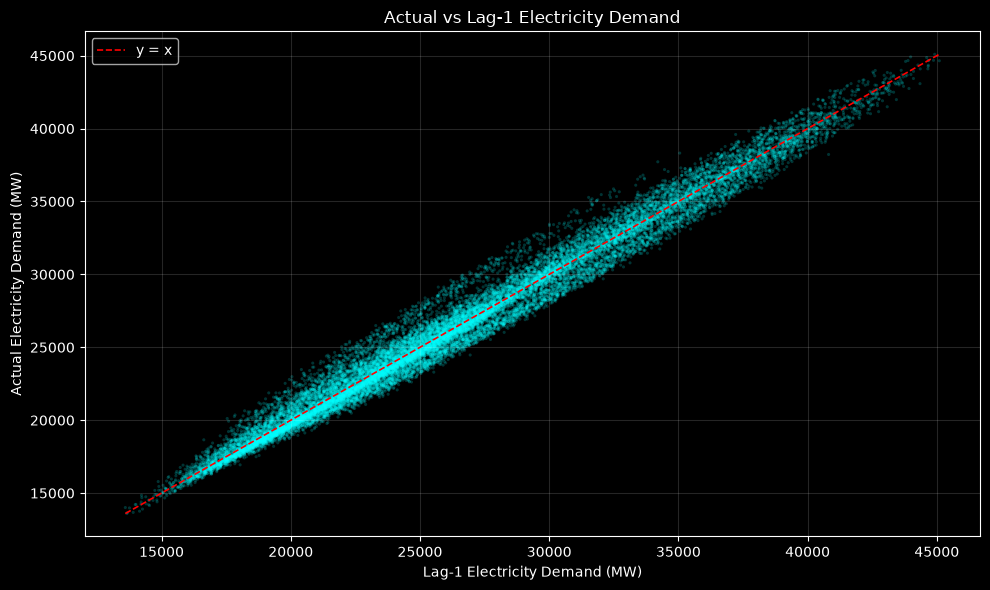

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    lag_pairs['demand_lag_1'],
    lag_pairs['demand_mw'],
    s=5,
    alpha=0.2,
    color='cyan',
    edgecolors='none'
)

# y = x reference line
min_val = min(lag_pairs['demand_lag_1'].min(), lag_pairs['demand_mw'].min())
max_val = max(lag_pairs['demand_lag_1'].max(), lag_pairs['demand_mw'].max())

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    linewidth=1.2,
    label='y = x'
)

ax.set(
    title='Actual vs Lag-1 Electricity Demand',
    xlabel='Lag-1 Electricity Demand (MW)',
    ylabel='Actual Electricity Demand (MW)'
)

ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [17]:
lag_pairs['demand_mw'].corr(lag_pairs['demand_lag_1']).item()

0.9892280000957202

In [18]:
train_set['demand_lag_48'] = train_set['demand_mw'].shift(48)
train_set['demand_lag_336'] = train_set['demand_mw'].shift(336)

In [19]:
lag_pairs = (
    train_set.dropna(
        subset=['demand_mw', 'demand_lag_48']
    )[['demand_mw', 'demand_lag_48']]
)

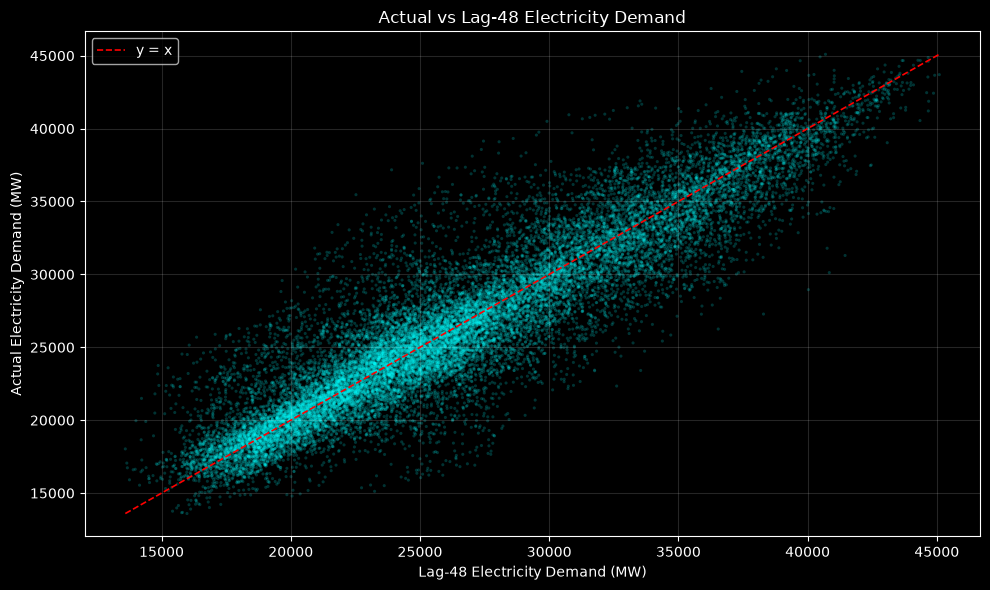

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    lag_pairs['demand_lag_48'],
    lag_pairs['demand_mw'],
    s=5,
    alpha=0.2,
    color='cyan',
    edgecolors='none'
)

# y = x reference line
min_val = min(lag_pairs['demand_lag_48'].min(), lag_pairs['demand_mw'].min())
max_val = max(lag_pairs['demand_lag_48'].max(), lag_pairs['demand_mw'].max())

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    linewidth=1.2,
    label='y = x'
)

ax.set(
    title='Actual vs Lag-48 Electricity Demand',
    xlabel='Lag-48 Electricity Demand (MW)',
    ylabel='Actual Electricity Demand (MW)'
)

ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [21]:
lag_pairs = (
    train_set.dropna(
        subset=['demand_mw', 'demand_lag_336']
    )[['demand_mw', 'demand_lag_336']]
)

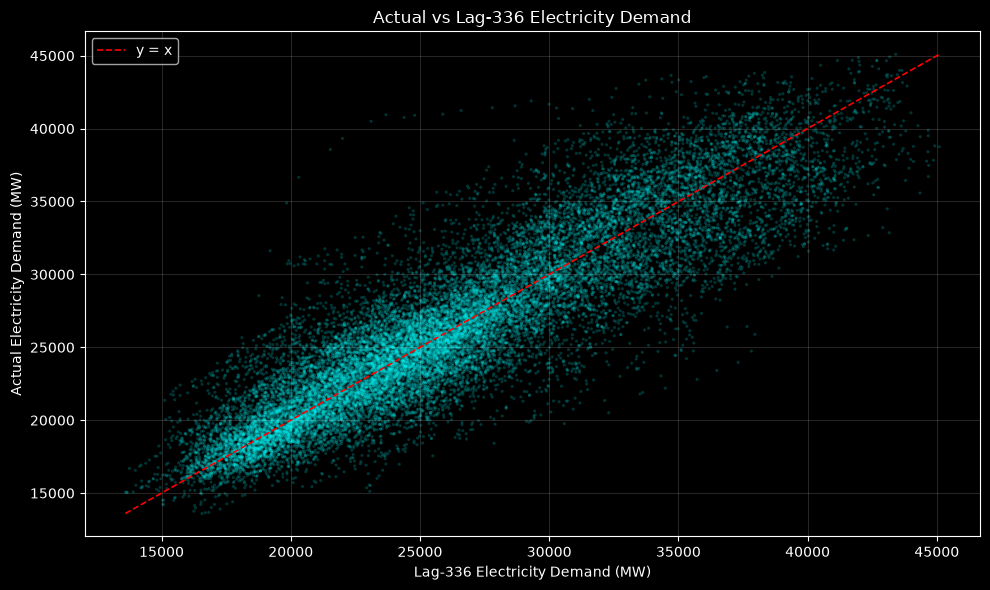

In [22]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    lag_pairs['demand_lag_336'],
    lag_pairs['demand_mw'],
    s=5,
    alpha=0.2,
    color='cyan',
    edgecolors='none'
)

# y = x reference line
min_val = min(lag_pairs['demand_lag_336'].min(), lag_pairs['demand_mw'].min())
max_val = max(lag_pairs['demand_lag_336'].max(), lag_pairs['demand_mw'].max())

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    linewidth=1.2,
    label='y = x'
)

ax.set(
    title='Actual vs Lag-336 Electricity Demand',
    xlabel='Lag-336 Electricity Demand (MW)',
    ylabel='Actual Electricity Demand (MW)'
)

ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [23]:
train_set['demand_mw'].corr(train_set['demand_lag_48']).item()

0.9142431502218531

In [24]:
train_set['demand_mw'].corr(train_set['demand_lag_336']).item()

0.892606113495373

## The Autocorrelation Curve

In [25]:
max_lag = 336

autocorrelation_df = pd.DataFrame({
    'lag': range(max_lag + 1),
    'autocorrelation': [
        train_set['demand_mw'].autocorr(lag=lag)
        for lag in range(max_lag + 1)
    ]
})

In [26]:
autocorrelation_df.head()

,lag,autocorrelation
0,0,1.000000
1,1,0.989228
2,2,0.960068
3,3,0.915219
4,4,0.859229


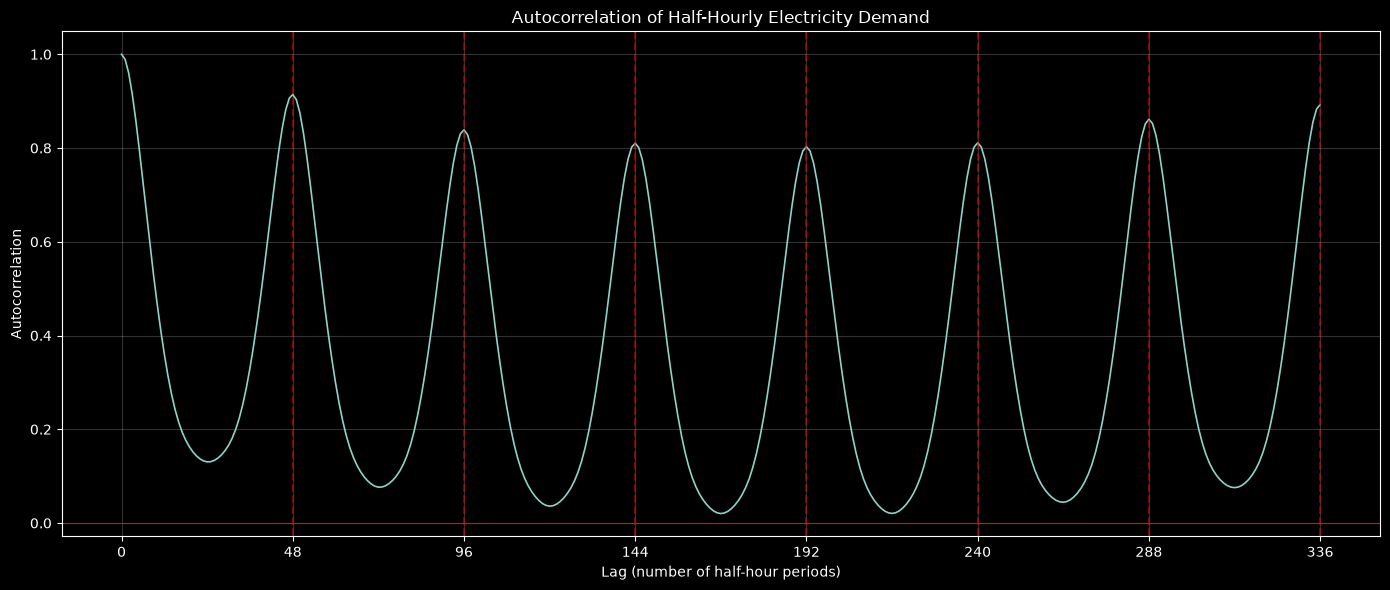

In [27]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    autocorrelation_df['lag'],
    autocorrelation_df['autocorrelation'],
    linewidth=1.2
)

ax.set(
    title='Autocorrelation of Half-Hourly Electricity Demand',
    xlabel='Lag (number of half-hour periods)',
    ylabel='Autocorrelation'
)

ax.axhline(0, color='red', linewidth=0.8)

for lag in range(48, 337, 48):
    ax.axvline(
        lag,
        color='red',
        linestyle='--',
        alpha=0.5
    )
    
ax.set_xticks(range(0, 337, 48))
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [28]:
important_lags = [0, 1, 2, 48, 96, 144, 192, 240, 288, 336]

important_autocorrelations = (
    autocorrelation_df
    .loc[autocorrelation_df['lag'].isin(important_lags)]
    .reset_index(drop=True)
)

In [29]:
important_autocorrelations

,lag,autocorrelation
0,0,1.000000
1,1,0.989228
2,2,0.960068
3,48,0.914243
4,96,0.838708
5,144,0.810371
6,192,0.802935
7,240,0.811194
8,288,0.861507
9,336,0.892606


- The auto correlation falls with lags but it fell till lag 192.. then it started increasing.. because of seasonality.. may be..
- There are reapeating peaks approximately every 48 lags.
- The 336 lag autocorr noticebly higher than the nearby lags.
- There are no negative auto correlations
- The curve clearly shows a daily seasonality and higher autocorr on 336 lag compared to nearby lags shows a weekly seasonality.. (kinda..)

### Formal ACF with 95% Confidence Bands

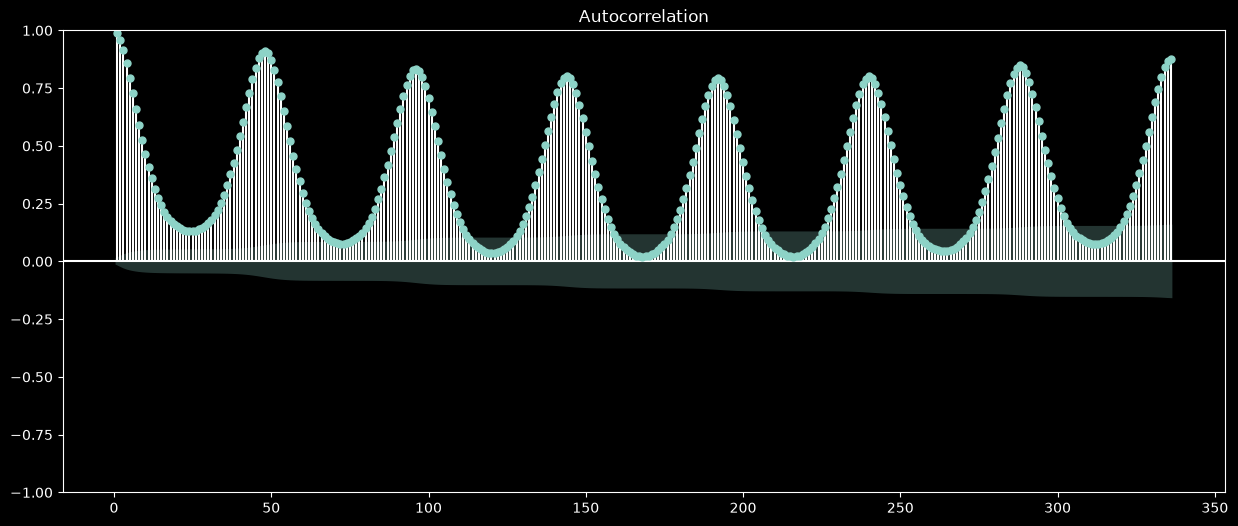

In [33]:
fig, ax = plt.subplots(figsize=(15, 6))
sm.graphics.tsa.plot_acf(
    train_set['demand_mw'],
    lags=336,
    alpha=0.05,
    fft=True,
    zero=False,
    ax=ax
)
plt.show()

#### Raw-Demand ACF: Zoomed Around the 95% Confidence Band

This second view deliberately clips the large autocorrelations so that the confidence band and the lags near zero correlation are easier to inspect. The full-scale plot above should be used to judge the magnitude and seasonal pattern.

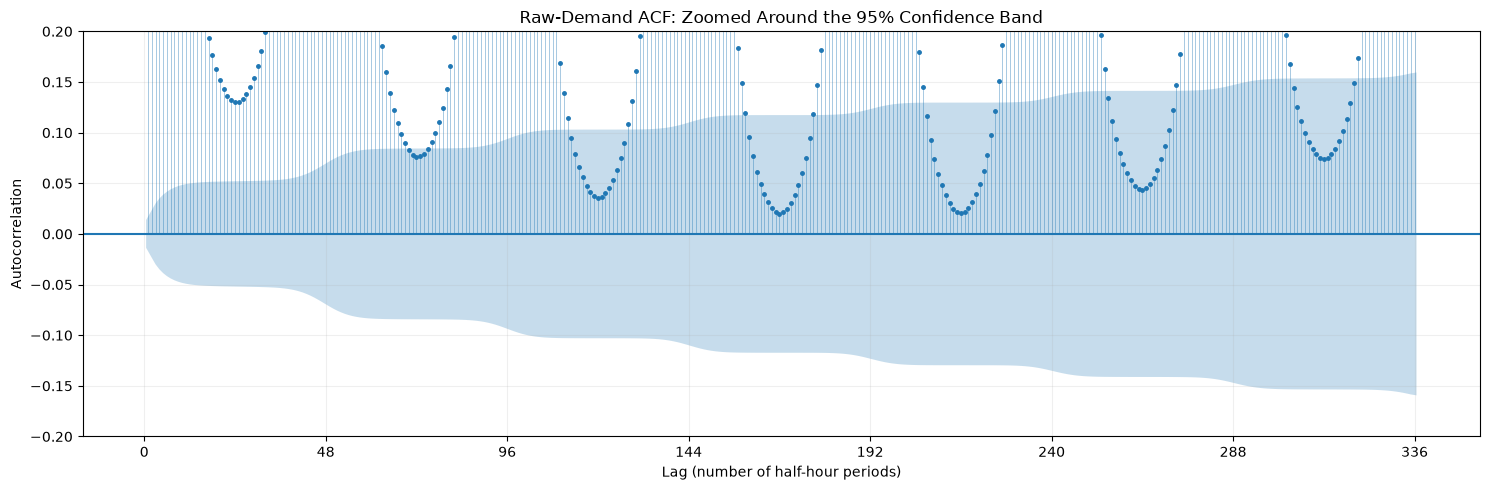

In [34]:
with plt.style.context('default'):
    fig, ax = plt.subplots(figsize=(15, 5))

    sm.graphics.tsa.plot_acf(
        train_set['demand_mw'],
        lags=336,
        alpha=0.05,
        fft=True,
        zero=False,
        ax=ax,
        markersize=2.5,
        vlines_kwargs={'linewidth': 0.5, 'alpha': 0.55}
    )

    ax.set(
        title='Raw-Demand ACF: Zoomed Around the 95% Confidence Band',
        xlabel='Lag (number of half-hour periods)',
        ylabel='Autocorrelation',
        ylim=(-0.20, 0.20)
    )
    ax.set_xticks(range(0, 337, 48))
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

### Construct The Weekly Seasonal-Naïve Forecast

Predict demand at a particular half-hour using the observed demand from exactly one week earlier.

In [74]:
dd_demand = pd.read_csv(project_root / 'data' / 'processed' / 'demand_development.csv')

In [75]:
dd_demand['timestamp_utc'] = pd.to_datetime(dd_demand['timestamp_utc'], utc=True)
dd_demand['timestamp_london'] = dd_demand['timestamp_utc'].dt.tz_convert('Europe/London')

In [76]:
dd_demand.sort_values(by='timestamp_utc', inplace=True)

In [77]:
dd_demand = (
    dd_demand
    .assign(
        weekly_naive_forecast_mw = dd_demand['demand_mw'].shift(336)
    )
)

In [78]:
dd_demand['data_split'].unique()

<StringArray>
['train', 'validation']
Length: 2, dtype: str

In [79]:
val_dd = dd_demand.loc[dd_demand['data_split'] == 'validation'].copy()

### Comparing Actual Demand with The Naive Forcasted Demand

In [80]:
compare = val_dd[['timestamp_utc', 'timestamp_london', 'demand_mw', 'weekly_naive_forecast_mw']]
compare.head()

,timestamp_utc,timestamp_london,demand_mw,weekly_naive_forecast_mw
20400,2024-03-01 00:00:00+00:00,2024-03-01 00:00:00+00:00,25373,24799.0
20401,2024-03-01 00:30:00+00:00,2024-03-01 00:30:00+00:00,25743,25173.0
20402,2024-03-01 01:00:00+00:00,2024-03-01 01:00:00+00:00,25410,24663.0
20403,2024-03-01 01:30:00+00:00,2024-03-01 01:30:00+00:00,24774,24033.0
20404,2024-03-01 02:00:00+00:00,2024-03-01 02:00:00+00:00,24340,23486.0


In [81]:
compare.info()

<class 'pandas.DataFrame'>
RangeIndex: 4414 entries, 20400 to 24813
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype                        
---  ------                    --------------  -----                        
 0   timestamp_utc             4414 non-null   datetime64[us, UTC]          
 1   timestamp_london          4414 non-null   datetime64[us, Europe/London]
 2   demand_mw                 4414 non-null   int64                        
 3   weekly_naive_forecast_mw  4414 non-null   float64                      
dtypes: datetime64[us, Europe/London](1), datetime64[us, UTC](1), float64(1), int64(1)
memory usage: 138.1 KB


In [82]:
compare['forecast_error'] = compare['demand_mw'].subtract(compare['weekly_naive_forecast_mw'])

In [83]:
mae = np.mean(np.abs(compare['forecast_error'])).item()
print(f"Mean Absolute Error: {mae}")

Mean Absolute Error: 1946.1746714997735


In [84]:
rmse = np.sqrt(np.mean(np.square(compare['forecast_error']))).item()
print(f'Root Mean Square Error: {rmse}')

Root Mean Square Error: 2541.244823339979


In [85]:
me = np.mean(compare['forecast_error']).item()
print(f'Mean Error: {me}')

Mean Error: -646.3744902582691


### Visualizing Actual V/S Naive Forecast

In [92]:
start = compare['timestamp_london'].min()
end = start + pd.Timedelta(weeks=1)

start, end

(Timestamp('2024-03-01 00:00:00+0000', tz='Europe/London'),
 Timestamp('2024-03-08 00:00:00+0000', tz='Europe/London'))

In [95]:
forecast_sam_weeek = compare.loc[
    (compare['timestamp_london'] >= start)
    &
    (compare['timestamp_london'] < end)
][['timestamp_london', 'demand_mw', 'weekly_naive_forecast_mw']]

In [96]:
forecast_sam_weeek.head()

,timestamp_london,demand_mw,weekly_naive_forecast_mw
20400,2024-03-01 00:00:00+00:00,25373,24799.0
20401,2024-03-01 00:30:00+00:00,25743,25173.0
20402,2024-03-01 01:00:00+00:00,25410,24663.0
20403,2024-03-01 01:30:00+00:00,24774,24033.0
20404,2024-03-01 02:00:00+00:00,24340,23486.0


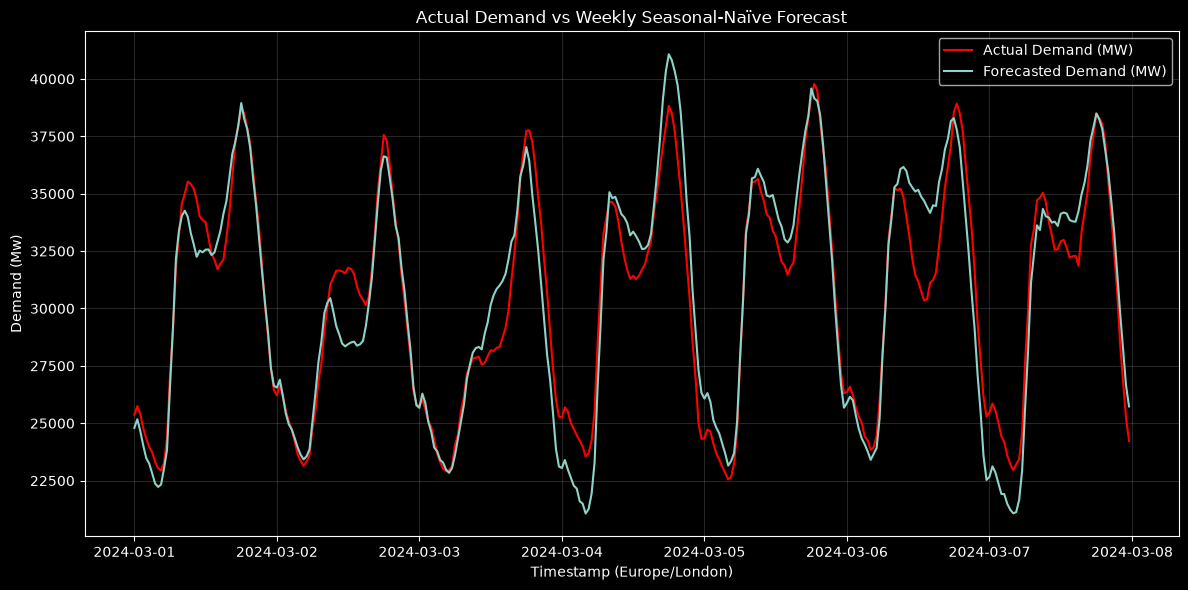

In [103]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    forecast_sam_weeek['timestamp_london'],
    forecast_sam_weeek['demand_mw'],
    color='red',
    label='Actual Demand (MW)'
)

ax.plot(
    forecast_sam_weeek['timestamp_london'],
    forecast_sam_weeek['weekly_naive_forecast_mw'],
    label='Forecasted Demand (MW)'
)

ax.set(
    title='Actual Demand vs Weekly Seasonal-Naïve Forecast',
    ylabel='Demand (Mw)',
    xlabel='Timestamp (Europe/London)'
)

ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

- Generally The naive forcast curve actually follows the actual demand really well.
- Surprisinly The peaks are almost accurately predicted.
- I think both curves differ most on 2024-03-06 and 2024-03-04
- The curves seem to overestimate the demand mostly around the peaks but seem to underestimate the troughs.
- The largest errors are around the midnight when the day starts and then around trhe first peak of the day.

### Numerically Verifying the Visual Observations

The plot provides useful initial impressions. The following summaries check whether those impressions are supported by the forecast errors.

In [104]:
weekly_error_check = forecast_sam_weeek.copy()

weekly_error_check['forecast_error'] = (
    weekly_error_check['demand_mw']
    - weekly_error_check['weekly_naive_forecast_mw']
)
weekly_error_check['absolute_error'] = weekly_error_check['forecast_error'].abs()
weekly_error_check['local_date'] = weekly_error_check['timestamp_london'].dt.date

#### Daily Error Summary

Daily MAE measures the typical size of a day's errors. Daily mean error retains the sign: a positive value means underforecasting, while a negative value means overforecasting.

In [105]:
daily_error_summary = (
    weekly_error_check
    .groupby('local_date')
    .agg(
        observations=('forecast_error', 'size'),
        mean_error_mw=('forecast_error', 'mean'),
        mae_mw=('absolute_error', 'mean')
    )
    .reset_index()
)

daily_error_summary.round(1)

,local_date,observations,mean_error_mw,mae_mw
0,2024-03-01,48,299.1,744.0
1,2024-03-02,48,574.0,892.3
2,2024-03-03,48,66.1,1124.5
3,2024-03-04,48,-404.9,1823.5
4,2024-03-05,48,-571.9,787.9
5,2024-03-06,48,-349.7,1650.9
6,2024-03-07,48,218.1,1367.9


#### Ten Largest Individual Errors

In [106]:
largest_errors = (
    weekly_error_check
    .nlargest(10, 'absolute_error')
    [[
        'timestamp_london',
        'demand_mw',
        'weekly_naive_forecast_mw',
        'forecast_error',
        'absolute_error'
    ]]
    .reset_index(drop=True)
)

largest_errors

,timestamp_london,demand_mw,weekly_naive_forecast_mw,forecast_error,absolute_error
0,2024-03-06 13:00:00+00:00,30346,34687.0,-4341.0,4341.0
1,2024-03-06 12:30:00+00:00,30752,34870.0,-4118.0,4118.0
2,2024-03-06 13:30:00+00:00,30408,34414.0,-4006.0,4006.0
3,2024-03-06 12:00:00+00:00,31175,35173.0,-3998.0,3998.0
4,2024-03-06 11:30:00+00:00,31468,35092.0,-3624.0,3624.0
5,2024-03-04 20:00:00+00:00,35173,38553.0,-3380.0,3380.0
6,2024-03-02 12:00:00+00:00,31776,28447.0,3329.0,3329.0
7,2024-03-06 14:30:00+00:00,31231,34492.0,-3261.0,3261.0
8,2024-03-04 19:30:00+00:00,36458,39706.0,-3248.0,3248.0
9,2024-03-02 12:30:00+00:00,31721,28521.0,3200.0,3200.0


#### Numerical Interpretation

The numerical checks support the initial observations that the weekly-naïve forecast reproduces the broad daily shape and that 4 March and 6 March are the two days with the greatest typical errors. However, the forecast does not consistently overpredict peaks and underpredict troughs: the sign of the daily mean error changes across the week. The largest individual errors occur mainly around midday on 6 March, the evening of 4 March, and midday on 2 March, rather than around midnight.